In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import pyremo as pr
import os
from openpyxl import load_workbook
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.patches as mpatches
from REMO2020TEB_mod import flip, parse_paris_time, get_paris_var_index, parisclass, modelclass_cities, prepare_remo_to_umask_seas, diurnal_metrics, df_to_latex_categ
os.environ['PATH'] = '/work/ch0636/g300096/Python/envs/kernelR2020TEB/bin:' + os.environ['PATH']

/work/ch0636/g300096/Python/envs/kernelR2020TEB/lib/python3.10/site-packages/pyremo/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
from dask.distributed import Client, progress
import dask
dask.config.set({'temporary_directory': '/scratch/g/g300096/dask/tmp'})
client = Client()
client

/work/ch0636/g300096/Python/envs/kernelR2020TEB/lib/python3.10/site-packages/distributed/node.py:187: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 44801 instead
  warnings.warn(


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /user/g300096/levante-spawner-preset//proxy/44801/status,
Dashboard: /user/g300096/levante-spawner-preset//proxy/44801/status,Workers: 16
Total threads: 256,Total memory: 235.37 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:35063,Workers: 0
Dashboard: /user/g300096/levante-spawner-preset//proxy/44801/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:42711,Total threads: 16
Dashboard: /user/g300096/levante-spawner-preset//proxy/41463/status,Memory: 14.71 GiB
Nanny: tcp://127.0.0.1:42779,


In [3]:
# give figure path
figpath = './figures/'

In [4]:
# Give the quantiles to be calculated (must inlcude 0.5)
quantiles = np.array([0.05,0.25,0.5,0.75,0.95])

In [5]:
# if we want to replace median with mean
lreplace_median=True

In [6]:
# Measurement data for Paris
paris_datapath = "/work/bg1369/FPS-URB-RCC/Urban_Observations_Paris/"
paris_data_nc = xr.open_dataset(paris_datapath+"Obs_MF_01_to_12_2020.nc")
paris_data_nc = parse_paris_time(paris_data_nc) # change time to datetime format
paris_data_xlsx = load_workbook(filename = paris_datapath+"Obs_MF.xlsx")

In [7]:
# Loop over different stations (51 currently)
paris_data =[] # init
pxls = paris_data_xlsx['Liste_Instruments']
for ii in range(51):
    paris_data.append(parisclass(pxls['D'+str(ii+2)].value,pxls['E'+str(ii+2)].value,pxls['F'+str(ii+2)].value,pxls['G'+str(ii+2)].value,pxls['K'+str(ii+2)].value))

In [8]:
# Stations to be used
paris_urb_stats = np.array(["Paris-Montsouris"])
paris_rur_stats = np.array(["Changis","Courdimanche","Dourdan","Melun","Pontoise","Prunay-Le-Temple"])

In [9]:
# Get all urban indexes (not Eifel-Tower) and rural indexes (Eiffel and double removal not really needed when using _stats)
paris_urb_ind = np.array([], dtype="int32")
paris_rur_ind = np.array([], dtype="int32")
for obj in paris_data:
    if(obj.vartype == "Urban" and any(paris_urb_stats[:] == obj.sitename) and obj.sitename != "Eiffel-Tower" and obj.sitename != "Paris-Montsouris-double"):
        paris_urb_ind = np.append(paris_urb_ind,obj.varind-1) # to python indexing
    if((obj.vartype == "Crops" or obj.vartype == "Forest") and any(paris_rur_stats[:] == obj.sitename)):
        paris_rur_ind = np.append(paris_rur_ind,obj.varind-1) # to python indexing

In [10]:
# calculate urban and rural means over the stations, and make seasonal diurnal means
paris_t2m_urban_raw = get_paris_var_index(paris_data_nc,"TEMPERATURE",paris_urb_ind,make_mean=True,addc=273.15).groupby(["season", "hour"])
paris_t2m_urban = paris_t2m_urban_raw.quantile(quantiles, dim='time')
paris_t2m_rural_raw = get_paris_var_index(paris_data_nc,"TEMPERATURE",paris_rur_ind,make_mean=True,addc=273.15).groupby(["season", "hour"])
paris_t2m_rural = paris_t2m_rural_raw.quantile(quantiles, dim='time')
paris_t2m_uhi_raw_all = (get_paris_var_index(paris_data_nc,"TEMPERATURE",paris_urb_ind,make_mean=True,addc=273.15)-get_paris_var_index(paris_data_nc,"TEMPERATURE",paris_rur_ind,make_mean=True,addc=273.15))
paris_t2m_uhi_raw = paris_t2m_uhi_raw_all.groupby(["season", "hour"])
paris_t2m_uhi = paris_t2m_uhi_raw.quantile(quantiles, dim='time')
if (lreplace_median):
    paris_t2m_urban.loc[dict(quantile=0.5)] = paris_t2m_urban_raw.mean("time")
    paris_t2m_rural.loc[dict(quantile=0.5)] = paris_t2m_rural_raw.mean("time")
    paris_t2m_uhi.loc[dict(quantile=0.5)] = paris_t2m_uhi_raw.mean("time")

In [11]:
# read in REMO hourly data
remo_datap = "/work/ch0636/g300096/results/TEB/post-processed"

In [12]:
# read in urban/rural mask
urb_rur_remo_mask_hr = xr.open_dataset("./data_in/model_data/REMO_static/urmask_Paris-ALPX-3_urclim_masks_fx.nc")
urb_rur_remo_mask_lr = xr.open_dataset("./data_in/model_data/REMO_static/urmask_Paris-EUR-11_urclim_masks_fx.nc")

In [13]:
# define the runs to be analysed
modelruns =[] # init

# 
modelruns.append(modelclass_cities("036047","REMO2020 TEB","ECOSG_LCZ",'b-','0.0275'))
modelruns.append(modelclass_cities("036048","REMO2020 TEB iMOVE","LANDMATE",'r-','0.0275'))
modelruns.append(modelclass_cities("036049","REMO2020","GLCC",'c-','0.0275'))
modelruns.append(modelclass_cities("036043","REMO2020 TEB","ECOSG_LCZ",'b--','0.11'))
modelruns.append(modelclass_cities("036044","REMO2020 TEB iMOVE","LANDMATE",'r--','0.11'))
modelruns.append(modelclass_cities("036041","REMO2020","GLCC",'c--','0.11'))
#modelruns.append(modelclass_cities("036042","REMO2020 iMOVE","LANDMATE",'g--','0.11'))

In [14]:
# read in data
for obj in modelruns:
    if (obj.reso == '0.0275'):
        obj.rawdata = xr.merge([pr.parse_dates(xr.open_dataset(remo_datap+"/"+obj.userexp+"_postpro_1h_2020.nc")),urb_rur_remo_mask_hr[obj.maskname]], compat="override", join="override")
    elif (obj.reso == '0.11'):
        obj.rawdata = xr.merge([pr.parse_dates(xr.open_dataset(remo_datap+"/"+obj.userexp+"_postpro_1h_2020.nc")),urb_rur_remo_mask_lr[obj.maskname]], compat="override", join="override")
    # Shift time by 30 minutes backwards (REMO specific)
    obj.rawdata = obj.rawdata.assign_coords(time=obj.rawdata.time - pd.Timedelta('60min'))
    obj.rawdata = obj.rawdata.assign_coords(
        season=obj.rawdata.time.dt.season,
        hour=obj.rawdata.time.dt.hour
    )

In [15]:
# prepare wanted variable
varname="TEMP2"
for obj in modelruns:
    obj.vardata = prepare_remo_to_umask_seas(obj.rawdata,obj.maskname,varname,lreplace_median,quantiles,luhi=True)

In [16]:
# Define the order of seasons to be used (also when plotting)
seasons = ["DJF","MAM","JJA","SON"]

In [17]:
# prepare statistics
rows = []
for seas in seasons:
    obs = paris_t2m_uhi.sel(season=seas).sel(quantile=0.5).values
    for obj in modelruns:
        mod = obj.vardata.uhi.sel(season=seas).sel(quantile=0.5).values
        metrics = diurnal_metrics(obs, mod)
        metrics["Season"] = seas
        metrics["Model"] = obj.runame
        metrics["Resolution"] = obj.reso
        rows.append(metrics)

res_diu = pd.DataFrame(rows)
res_diu = res_diu[["Model", "Resolution", "Season"] + [col for col in res_diu.columns 
                               if col not in ["Model", "Resolution",  "Season"]]]

In [18]:
# create table for LaTeX (uncomment print to see it)
latex_code = df_to_latex_categ(res_diu)
#print(latex_code)

In [19]:
# select plotted quantiles for shading (and 1-q)
ploquan = [0.05,0.25]

### Prepare some common plotting configs

In [20]:
# Reset and set rcParams
mpl.rcParams.update(mpl.rcParamsDefault)
#plt.rcParams["figure.figsize"] = (25, 25)
plt.rcParams["figure.subplot.wspace"] = 0.3
plt.rcParams["axes.titlesize"] = 26
plt.rcParams['axes.labelsize'] = 22
plt.rcParams["xtick.top"] = True
plt.rcParams["xtick.labeltop"] = False
plt.rcParams["xtick.bottom"] = True
plt.rcParams["xtick.labelbottom"] = True
plt.rcParams["ytick.left"] = True
plt.rcParams["ytick.labelleft"] = True
plt.rcParams["ytick.right"] = True
plt.rcParams["ytick.labelright"] = False
plt.rcParams['lines.markersize'] = 10
plt.rc('text', usetex=True)
plt.rc('font', family='serif')
plt.rc('xtick', labelsize=24) 
plt.rc('ytick', labelsize=24) 
plt.rc('legend', fontsize=22)

# Prepare temperature plots

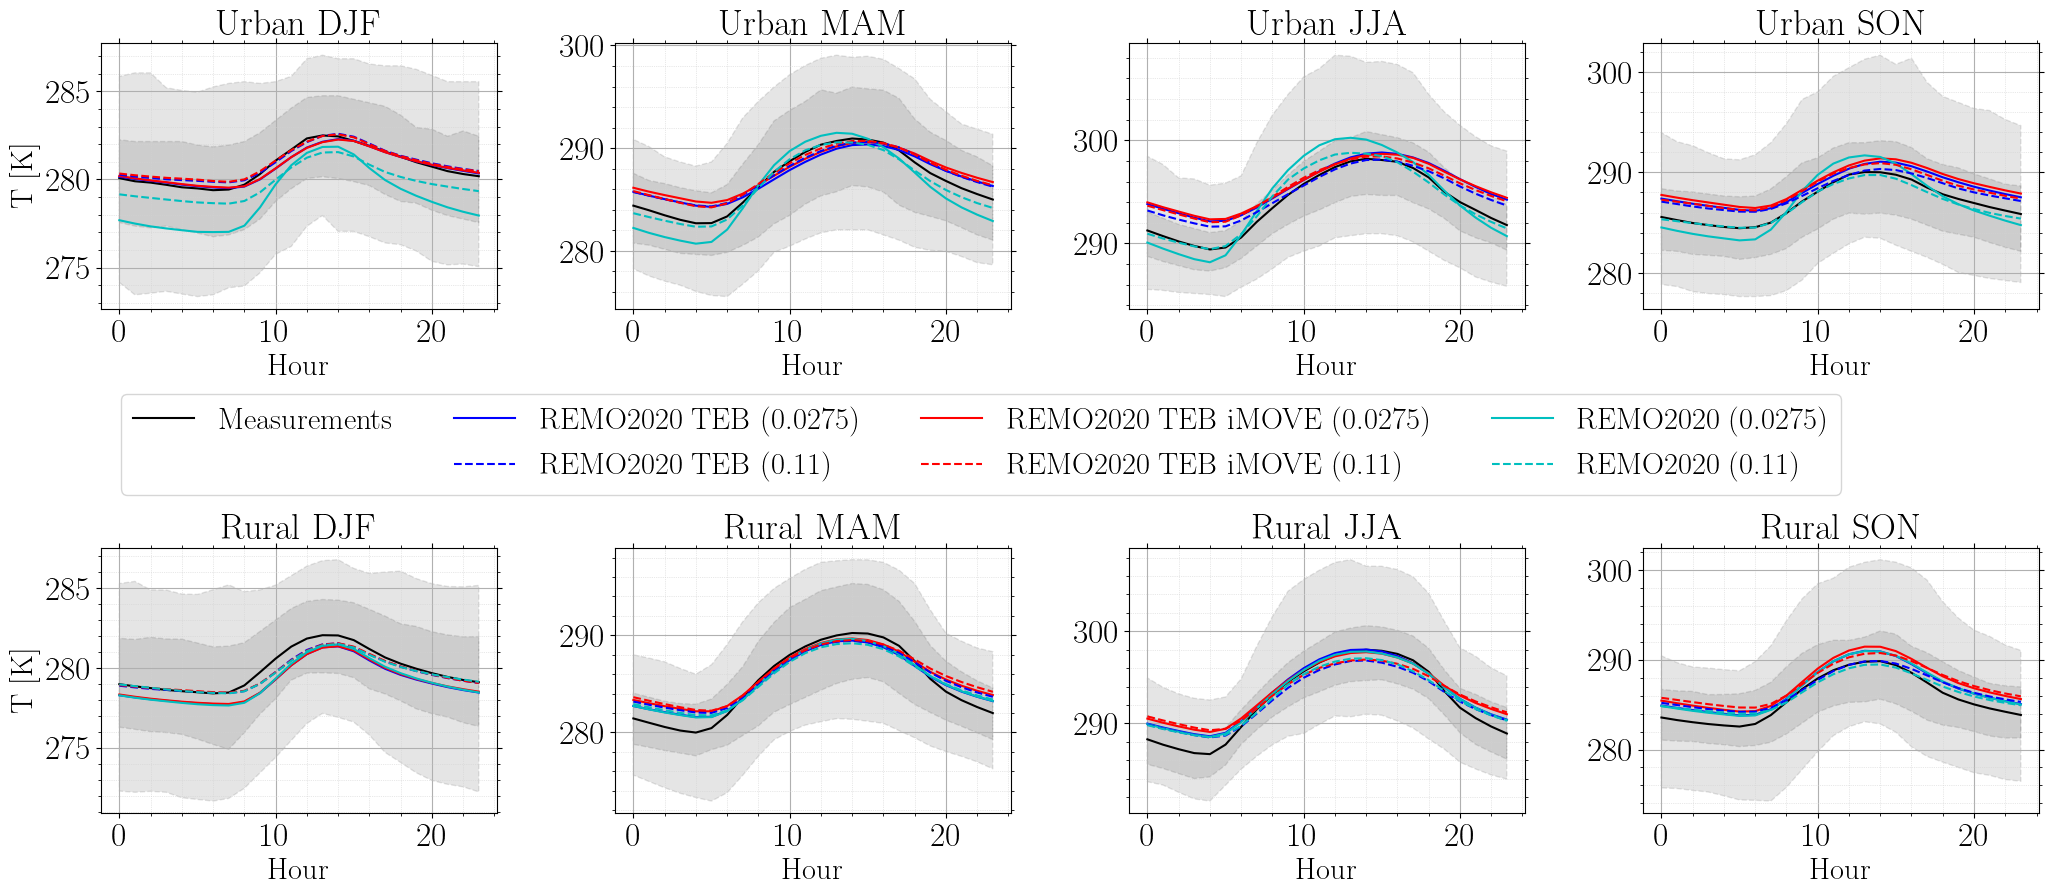

In [21]:
# plot specific configs
plt.rcParams["figure.subplot.hspace"] = 0.9
# Create subplots: 2 rows, 4 columns
fig, ax = plt.subplots(2, 4, figsize=(25, 10))
ax = ax.flatten()  # Flatten for easy indexing

# number of legend columns
ncol = 4
# some helper indexes
ind = 0
for seas in seasons:
    ax[ind].grid() # make grid and modify it
    ax[ind].grid(which='minor', color='lightgrey', linestyle=':', linewidth=0.5)
    ax[ind].minorticks_on() # use minor ticks
    ax[ind + len(seasons)].grid() # make grid and modify it
    ax[ind + len(seasons)].grid(which='minor', color='lightgrey', linestyle=':', linewidth=0.5)
    ax[ind + len(seasons)].minorticks_on() # use minor ticks
    # Urban plot
    ax[ind].plot(paris_t2m_urban.hour.values,
                 paris_t2m_urban.sel(season=seas).sel(quantile=0.5).values,
                 'k-', label="Measurements")
    for qq in ploquan:
        ax[ind].fill_between(paris_t2m_urban.hour.values,
                            paris_t2m_urban.sel(season=seas).sel(quantile=qq).values, paris_t2m_urban.sel(season=seas).sel(quantile=1.0-qq).values,
                            color='k', alpha=0.1, linewidth=1, linestyle = '--')
    
    for obj in modelruns:
        ax[ind].plot(obj.vardata.hour.values,
                     obj.vardata.urban.sel(season=seas).sel(quantile=0.5).values,
                     obj.plstyle, label=obj.runame+" ("+obj.reso+")")

#        for qq in ploquan:
#            ax[ind].fill_between(obj.vardata.hour.values,
#                                obj.vardata.urban.sel(season=seas).sel(quantile=qq).values, obj.vardata.urban.sel(season=seas).sel(quantile=1.0-qq).values,
#                                color=obj.plstyle[0], alpha=0.1, linewidth=1, linestyle = '--')
    ax[ind].set_title(f"Urban {seas}")
    ax[ind].set_xlabel("Hour")
    if seas == "DJF":
        ax[ind].set_ylabel("T [K]")
        # flip and insert one empty string
        handles, labels = ax[ind].get_legend_handles_labels()
        empty_patch = mpatches.Patch(color='none', label='') # create a patch with no color
        handles.insert(ncol, empty_patch)
        labels.insert(ncol,'')
        ax[ind].legend(flip(handles, ncol), flip(labels, ncol),loc=(0.05, -0.7), ncol=ncol, frameon=True)
    
    # Rural plot
    ax[ind + len(seasons)].plot(paris_t2m_rural.hour.values,
                                paris_t2m_rural.sel(season=seas).sel(quantile=0.5).values,
                                'k-', label="Measurements")
    for qq in ploquan:
        ax[ind + len(seasons)].fill_between(paris_t2m_rural.hour.values,
                            paris_t2m_rural.sel(season=seas).sel(quantile=qq).values, paris_t2m_rural.sel(season=seas).sel(quantile=1.0-qq).values,
                            color='k', alpha=0.1, linewidth=1, linestyle = '--')
    for obj in modelruns:
        ax[ind + len(seasons)].plot(obj.vardata.hour.values,
                                    obj.vardata.rural.sel(season=seas).sel(quantile=0.5).values,
                                    obj.plstyle, label=obj.runame+" ("+obj.reso+")")
#        for qq in ploquan:
#            ax[ind + len(seasons)].fill_between(obj.vardata.hour.values,
#                                obj.vardata.rural.sel(season=seas).sel(quantile=qq).values, obj.vardata.rural.sel(season=seas).sel(quantile=1.0-qq).values,
#                                color=obj.plstyle[0], alpha=0.1, linewidth=1, linestyle = '--') 
    ax[ind + len(seasons)].set_title(f"Rural {seas}")
    ax[ind + len(seasons)].set_xlabel("Hour")
    if seas == "DJF":
        ax[ind + len(seasons)].set_ylabel("T [K]")
    # increase counter
    ind += 1
    
plt.savefig(figpath + 'fig13.png', format="png", bbox_inches='tight', pad_inches=0)
plt.show()

### Prepare UHI plots

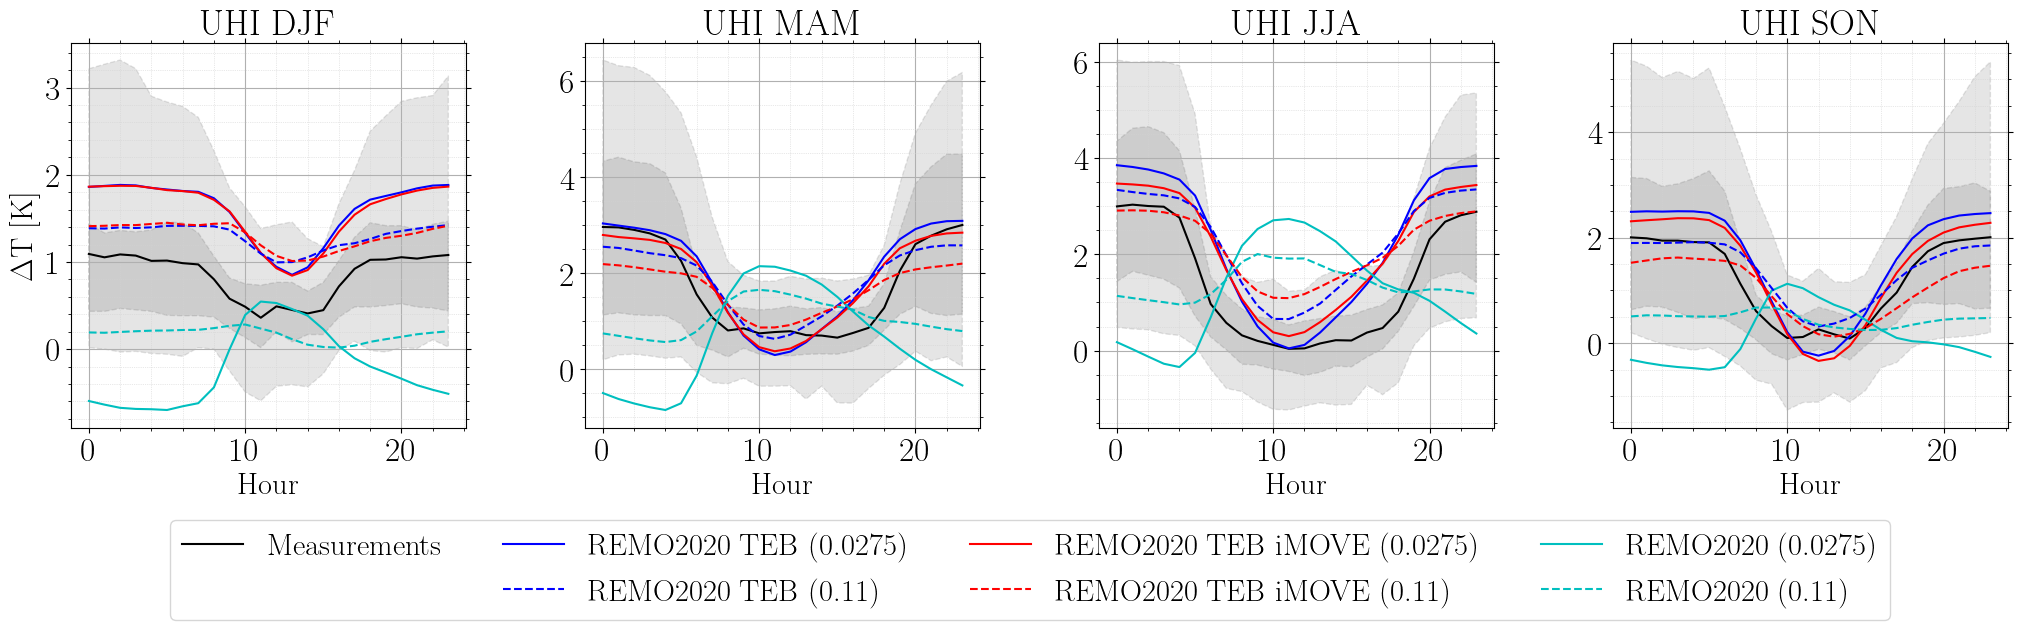

In [22]:
# plot specific configs
plt.rcParams["figure.subplot.hspace"] = 0.7
# Create subplots: 1 row, 4 columns
fig, ax = plt.subplots(1, 4, figsize=(25, 5))
ax = ax.flatten()  # Flatten for easy indexing

# number of legend columns
ncol = 4
# some helper indexes
ind = 0
for seas in seasons:
    ax[ind].grid() # make grid and modify it
    ax[ind].grid(which='minor', color='lightgrey', linestyle=':', linewidth=0.5)
    ax[ind].minorticks_on() # use minor ticks
    # UHI plot
    ax[ind].plot(paris_t2m_uhi.hour.values,
                 paris_t2m_uhi.sel(season=seas).sel(quantile=0.5).values,
                 'k-', label="Measurements")
    for qq in ploquan:
        ax[ind].fill_between(paris_t2m_uhi.hour.values,
                            paris_t2m_uhi.sel(season=seas).sel(quantile=qq).values, paris_t2m_uhi.sel(season=seas).sel(quantile=1.0-qq).values,
                            color='k', alpha=0.1, linewidth=1, linestyle = '--')
    
    for obj in modelruns:
        ax[ind].plot(obj.vardata.hour.values,
                     obj.vardata.uhi.sel(season=seas).sel(quantile=0.5).values,
                     obj.plstyle, label=obj.runame+" ("+obj.reso+")")
#        for qq in ploquan:
#            ax[ind].fill_between(obj.vardata.hour.values,
#                                obj.vardata.uhi.sel(season=seas).sel(quantile=qq).values, obj.vardata.uhi.sel(season=seas).sel(quantile=1.0-qq).values,
#                                color=obj.plstyle[0], alpha=0.1, linewidth=1, linestyle = '--')
    ax[ind].set_title(f"UHI {seas}")
    ax[ind].set_xlabel("Hour")
    if seas == "DJF":
        ax[ind].set_ylabel("$\Delta$T [K]")
        # flip and insert one empty string
        handles, labels = ax[ind].get_legend_handles_labels()
        empty_patch = mpatches.Patch(color='none', label='') # create a patch with no color
        handles.insert(ncol, empty_patch)
        labels.insert(ncol,'')
        ax[ind].legend(flip(handles, ncol), flip(labels, ncol),loc=(0.25, -0.5), ncol=ncol, frameon=True)
    # increase counter
    ind += 1

plt.savefig(figpath + 'fig6.png', format="png", bbox_inches='tight', pad_inches=0)
plt.show()